Tugas Praktikum 2 & 3 — Modul 2 Pre-Processing Data
Dataset: Auto MPG (UCI Machine Learning Repository)

Raden Affan Harits Taufik (163241037)

1. Load Dataset

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
                'acceleration', 'model_year', 'origin', 'car_name']
 
auto_df = pd.read_csv(url, sep=r'\s+', header=None, names=column_names,
                       na_values='?')
raw_df = auto_df.copy()
print(auto_df.shape)
auto_df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


Data Cleaning Level 1

In [16]:
auto_df.info()
print("\nJumlah nama mobil yang duplikat:", auto_df['car_name'].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB

Jumlah nama mobil yang duplikat: 93


In [17]:
print("Contoh data mentah (5 baris pertama):")
print(raw_df.head().to_string(index=False))

print("\nBaris dengan missing value (horsepower = NaN) SEBELUM preprocessing:")
print(raw_df[raw_df.isna().any(axis=1)].to_string(index=False))

Contoh data mentah (5 baris pertama):
 mpg  cylinders  displacement  horsepower  weight  acceleration  model_year  origin                  car_name
18.0          8         307.0       130.0  3504.0          12.0          70       1 chevrolet chevelle malibu
15.0          8         350.0       165.0  3693.0          11.5          70       1         buick skylark 320
18.0          8         318.0       150.0  3436.0          11.0          70       1        plymouth satellite
16.0          8         304.0       150.0  3433.0          12.0          70       1             amc rebel sst
17.0          8         302.0       140.0  3449.0          10.5          70       1               ford torino

Baris dengan missing value (horsepower = NaN) SEBELUM preprocessing:
 mpg  cylinders  displacement  horsepower  weight  acceleration  model_year  origin             car_name
25.0          4          98.0         NaN  2046.0          19.0          71       1           ford pinto
21.0          6       

2. Statistik Deskriptif, Missing Value, dan Outlier untuk Atribut 1–8

In [18]:
attributes = column_names[:8]
auto_df[attributes] = auto_df[attributes].apply(pd.to_numeric, errors='coerce')

stats_table = pd.DataFrame({
    'Atribut': attributes,
    'Mean': [auto_df[col].mean() for col in attributes],
    'Max': [auto_df[col].max() for col in attributes],
    'Min': [auto_df[col].min() for col in attributes],
    'Modus': [auto_df[col].mode().iloc[0] for col in attributes],
    'Missing Value/NaN': [auto_df[col].isna().sum() for col in attributes]
})

stats_table.style.format({
    'Mean': '{:.2f}',
    'Max': '{:.2f}',
    'Min': '{:.2f}',
    'Modus': '{:.2f}',
    'Missing Value/NaN': '{:.0f}'
})

,Atribut,Mean,Max,Min,Modus,Missing Value/NaN
0,mpg,23.51,46.60,9.00,13.00,0
1,cylinders,5.45,8.00,3.00,4.00,0
2,displacement,193.43,455.00,68.00,97.00,0
3,horsepower,104.47,230.00,46.00,150.00,6
4,weight,2970.42,5140.00,1613.00,1985.00,0
5,acceleration,15.57,24.80,8.00,14.50,0
6,model_year,76.01,82.00,70.00,73.00,0
7,origin,1.57,3.00,1.00,1.00,0


3. Diagnosa Outlier (Boxplot per Atribut Numerik Kontinu)

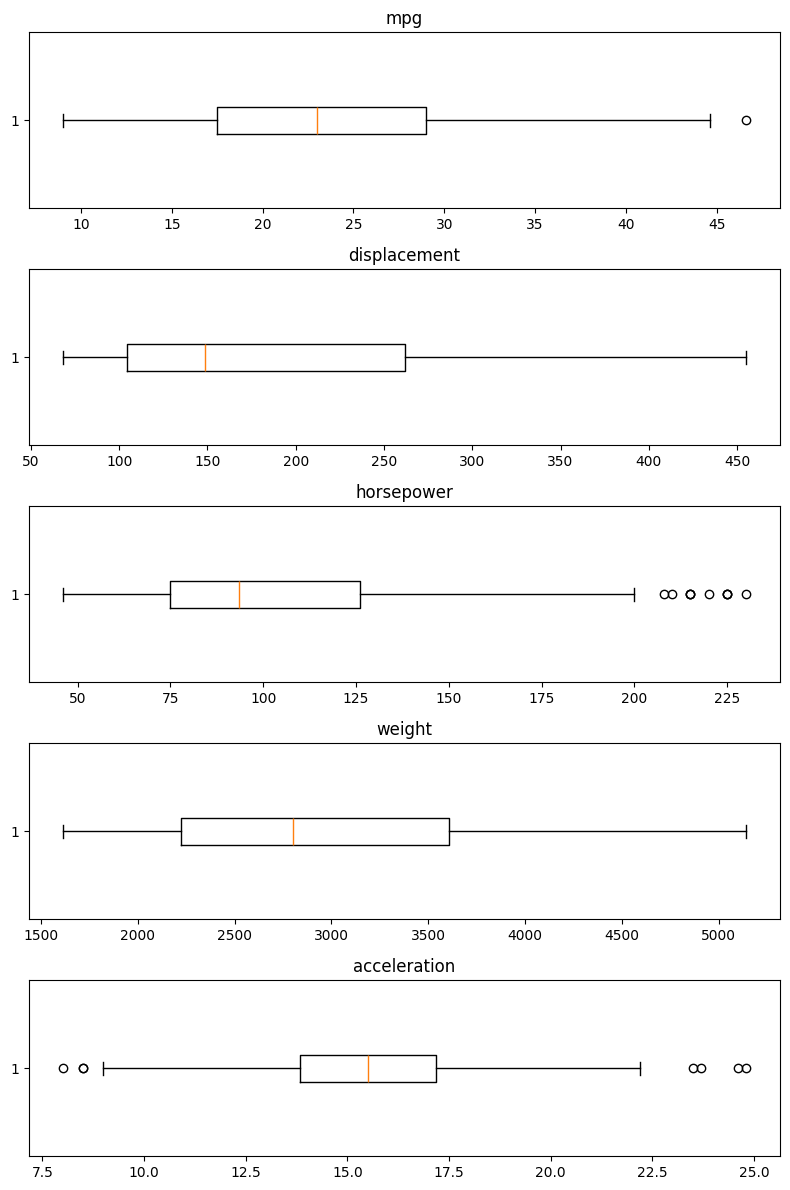

In [19]:
numeric_attrs = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']
 
fig, axes = plt.subplots(len(numeric_attrs), 1, figsize=(8, 12))
for ax, col in zip(axes, numeric_attrs):
    ax.boxplot(auto_df[col].dropna(), vert=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [20]:
def detect_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]
 
for col in numeric_attrs:
    outliers = detect_outliers_iqr(auto_df[col].dropna())
    print(f"{col}: {len(outliers)} outlier ditemukan")
    if len(outliers) > 0:
        print(auto_df.loc[outliers.index, ['car_name', col]].to_string(index=False))
    print()

mpg: 1 outlier ditemukan
 car_name  mpg
mazda glc 46.6

displacement: 0 outlier ditemukan

horsepower: 10 outlier ditemukan
                    car_name  horsepower
            chevrolet impala       220.0
           plymouth fury iii       215.0
            pontiac catalina       225.0
     buick estate wagon (sw)       225.0
                   ford f250       215.0
                  dodge d200       210.0
             mercury marquis       208.0
chrysler new yorker brougham       215.0
    buick electra 225 custom       225.0
          pontiac grand prix       230.0

weight: 0 outlier ditemukan

acceleration: 7 outlier ditemukan
          car_name  acceleration
 plymouth fury iii           8.5
amc ambassador dpl           8.5
plymouth 'cuda 340           8.0
 volkswagen type 3          23.5
       peugeot 504          24.8
vw dasher (diesel)          23.7
         vw pickup          24.6



Tugas 3 - Penanganan Missing Value

Kolom 'mpg' diisi dengan nilai mean
Kolom 'horsepower' diisi dengan nilai modus

In [21]:
print("Missing value SEBELUM penanganan:")
print(auto_df.isna().sum())

auto_df['mpg'].fillna(auto_df['mpg'].mean(), inplace=True)
auto_df['horsepower'] = auto_df['horsepower'].fillna(auto_df['horsepower'].mode().iloc[0])

print("\nMissing value SETELAH penanganan:")
print(auto_df.isna().sum())

Missing value SEBELUM penanganan:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Missing value SETELAH penanganan:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


C:\Users\USER\AppData\Local\Temp\ipykernel_30080\919365705.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  auto_df['mpg'].fillna(auto_df['mpg'].mean(), inplace=True)


In [22]:
missing_idx = raw_df[raw_df.isna().any(axis=1)].index

print("Baris yang sama, SEBELUM (raw) vs SESUDAH (cleaned):\n")
print("SEBELUM")
print(raw_df.loc[missing_idx, ['car_name', 'mpg', 'horsepower']].to_string(index=False))

print("\nSESUDAH")
print(auto_df.loc[missing_idx, ['car_name', 'mpg', 'horsepower']].to_string(index=False))

Baris yang sama, SEBELUM (raw) vs SESUDAH (cleaned):

SEBELUM
            car_name  mpg  horsepower
          ford pinto 25.0         NaN
       ford maverick 21.0         NaN
renault lecar deluxe 40.9         NaN
  ford mustang cobra 23.6         NaN
         renault 18i 34.5         NaN
      amc concord dl 23.0         NaN

SESUDAH
            car_name  mpg  horsepower
          ford pinto 25.0       150.0
       ford maverick 21.0       150.0
renault lecar deluxe 40.9       150.0
  ford mustang cobra 23.6       150.0
         renault 18i 34.5       150.0
      amc concord dl 23.0       150.0


In [23]:
print("Ringkasan dataset SEBELUM preprocessing:")
print(raw_df.describe(include='all').loc[['count', 'mean', 'min', 'max']])

print("\nRingkasan dataset SESUDAH preprocessing:")
print(auto_df.describe(include='all').loc[['count', 'mean', 'min', 'max']])

Ringkasan dataset SEBELUM preprocessing:
              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  392.000000   398.000000   
mean    23.514573    5.454774    193.425879  104.469388  2970.424623   
min      9.000000    3.000000     68.000000   46.000000  1613.000000   
max     46.600000    8.000000    455.000000  230.000000  5140.000000   

       acceleration  model_year      origin car_name  
count     398.00000   398.00000  398.000000      398  
mean       15.56809    76.01005    1.572864      NaN  
min         8.00000    70.00000    1.000000      NaN  
max        24.80000    82.00000    3.000000      NaN  

Ringkasan dataset SESUDAH preprocessing:
              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  398.000000   398.000000   
mean    23.514573    5.454774    193.425879  105.155779  2970.424623   
min      9.000000    3.000000     68.000000   46.000000  1613.000

4. Penerapan Data Reduction dengan Regresi Linier



In [27]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# car_name bersifat tekstual; origin dipertahankan sebagai kode numerik agar konsisten
feature_cols = ['cylinders', 'displacement', 'horsepower', 'weight',
                'acceleration', 'model_year', 'origin']
target_col = 'mpg'
model_df = auto_df[feature_cols + [target_col]].dropna().copy()

X = model_df[feature_cols]
y = model_df[target_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Model penuh: seluruh atribut digunakan untuk memprediksi mpg.
full_model = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])
full_model.fit(X_train, y_train)

# Koefisien pada skala standar dapat dibandingkan antaratribut.
standardized_coef = pd.Series(
    full_model.named_steps['regressor'].coef_, index=feature_cols
).sort_values(key=np.abs, ascending=False)
selected_features = standardized_coef.abs().head(4).index.tolist()

reduced_model = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])
reduced_model.fit(X_train[selected_features], y_train)

pred_full = full_model.predict(X_test)
pred_reduced = reduced_model.predict(X_test[selected_features])

def evaluate_model(name, y_true, prediction, n_features):
    return {
        'Model': name,
        'Jumlah fitur': n_features,
        'MAE': mean_absolute_error(y_true, prediction),
        'RMSE': np.sqrt(mean_squared_error(y_true, prediction)),
        'R2': r2_score(y_true, prediction)
    }

results = pd.DataFrame([
    evaluate_model('Model penuh', y_test, pred_full, len(feature_cols)),
    evaluate_model('Model tereduksi', y_test, pred_reduced, len(selected_features))
])

print('Urutan pengaruh fitur berdasarkan "koefisien standar":')
print(standardized_coef.to_string())
print('\nFitur yang dipertahankan:', selected_features)
print('\nPerbandingan performa pada data uji:')
display(results.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R2': '{:.3f}'}))




Urutan pengaruh fitur berdasarkan "koefisien standar":
weight         -5.785323
model_year      2.885263
displacement    1.347436
origin          1.037626
acceleration    0.274425
cylinders      -0.236058
horsepower     -0.231210

Fitur yang dipertahankan: ['weight', 'model_year', 'displacement', 'origin']

Perbandingan performa pada data uji:


,Model,Jumlah fitur,MAE,RMSE,R2
0,Model penuh,7,2.248,2.863,0.848
1,Model tereduksi,4,2.249,2.914,0.842


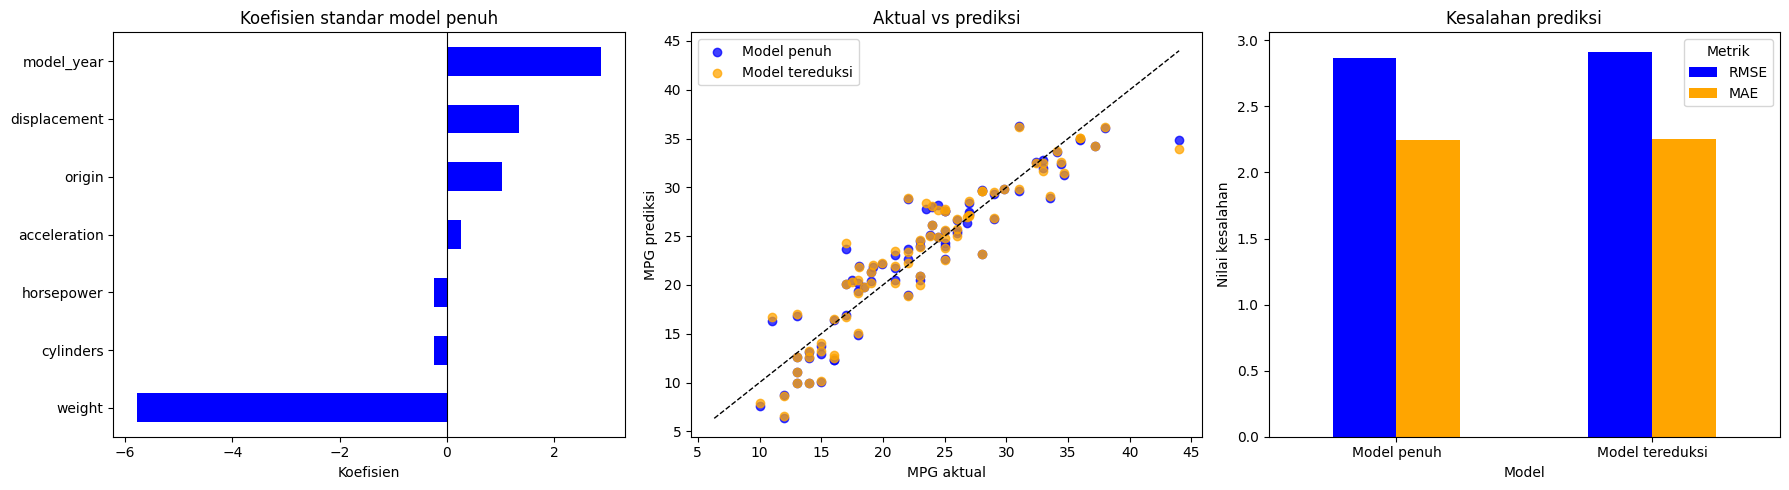

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

standardized_coef.sort_values().plot(kind='barh', ax=axes[0], color='blue')
axes[0].set_title('Koefisien standar model penuh')
axes[0].set_xlabel('Koefisien')
axes[0].axvline(0, color='black', linewidth=0.8)

axes[1].scatter(y_test, pred_full, alpha=0.75, color='blue', label='Model penuh')
axes[1].scatter(y_test, pred_reduced, alpha=0.75, color='orange', label='Model tereduksi')
line_min = min(y_test.min(), pred_full.min(), pred_reduced.min())
line_max = max(y_test.max(), pred_full.max(), pred_reduced.max())
axes[1].plot([line_min, line_max], [line_min, line_max], 'k--', linewidth=1)
axes[1].set_title('Aktual vs prediksi')
axes[1].set_xlabel('MPG aktual')
axes[1].set_ylabel('MPG prediksi')
axes[1].legend()

metric_names = ['RMSE', 'MAE']
metric_values = results.set_index('Model')[metric_names]
metric_values.plot(kind='bar', ax=axes[2], color=['blue', 'orange'])
axes[2].set_title('Kesalahan prediksi')
axes[2].set_ylabel('Nilai kesalahan')
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(title='Metrik')

plt.tight_layout()
plt.show()

full_r2 = results.loc[results['Model'] == 'Model penuh', 'R2'].iloc[0]
reduced_r2 = results.loc[results['Model'] == 'Model tereduksi', 'R2'].iloc[0]
rmse_change = (results.loc[results['Model'] == 'Model tereduksi', 'RMSE'].iloc[0] /
               results.loc[results['Model'] == 'Model penuh', 'RMSE'].iloc[0] - 1) * 100

5. Rescale, Binarize, dan Standardize Data



In [ ]:
from sklearn.preprocessing import MinMaxScaler, Binarizer, StandardScaler

preprocess_cols = ['cylinders', 'displacement', 'horsepower', 'weight',
                   'acceleration', 'model_year', 'origin']
preprocess_df = auto_df[preprocess_cols].dropna().copy()

# Rescale: setiap atribut berada pada rentang 0 sampai 1.
minmax_scaler = MinMaxScaler()
rescaled_df = pd.DataFrame(
    minmax_scaler.fit_transform(preprocess_df),
    columns=preprocess_cols,
    index=preprocess_df.index
)

# Binarize: model_year >= median dikategorikan sebagai mobil relatif baru.
year_threshold = preprocess_df['model_year'].median()
binarizer = Binarizer(threshold=year_threshold)
binarized_year = binarizer.fit_transform(preprocess_df[['model_year']]).ravel()
binarized_df = pd.DataFrame(
    {'model_year_binary': binarized_year.astype(int)},
    index=preprocess_df.index
)
binarized_df['kategori'] = binarized_df['model_year_binary'].map({
    0: f'Lama (< {year_threshold:.0f})',
    1: f'Baru (>= {year_threshold:.0f})'
})

# Standardize: rata-rata mendekati 0 dan simpangan baku populasi mendekati 1.
standard_scaler = StandardScaler()
standardized_df = pd.DataFrame(
    standard_scaler.fit_transform(preprocess_df),
    columns=preprocess_cols,
    index=preprocess_df.index
)

summary = pd.DataFrame({
    'Original_mean': preprocess_df.mean(),
    'Original_std': preprocess_df.std(ddof=0),
    'Rescale_min': rescaled_df.min(),
    'Rescale_max': rescaled_df.max(),
    'Standardize_mean': standardized_df.mean(),
    'Standardize_std': standardized_df.std(ddof=0)
})

print('\nProporsi kategori hasil binarize:')
print(binarized_df['kategori'].value_counts(normalize=True).mul(100).round(2).astype(str).add('%'))
print('\nRingkasan transformasi:')
display(summary.style.format('{:.3f}'))



Proporsi kategori hasil binarize:
kategori
Lama (< 76)     54.27%
Baru (>= 76)    45.73%
Name: proportion, dtype: object

Ringkasan transformasi:


,Original_mean,Original_std,Rescale_min,Rescale_max,Standardize_mean,Standardize_std
cylinders,5.455,1.699,0.000,1.000,-0.000,1.000
displacement,193.426,104.139,0.000,1.000,-0.000,1.000
horsepower,105.156,38.552,0.000,1.000,-0.000,1.000
weight,2970.425,845.777,0.000,1.000,-0.000,1.000
acceleration,15.568,2.754,0.000,1.000,-0.000,1.000
model_year,76.010,3.693,0.000,1.000,-0.000,1.000
origin,1.573,0.801,0.000,1.000,-0.000,1.000


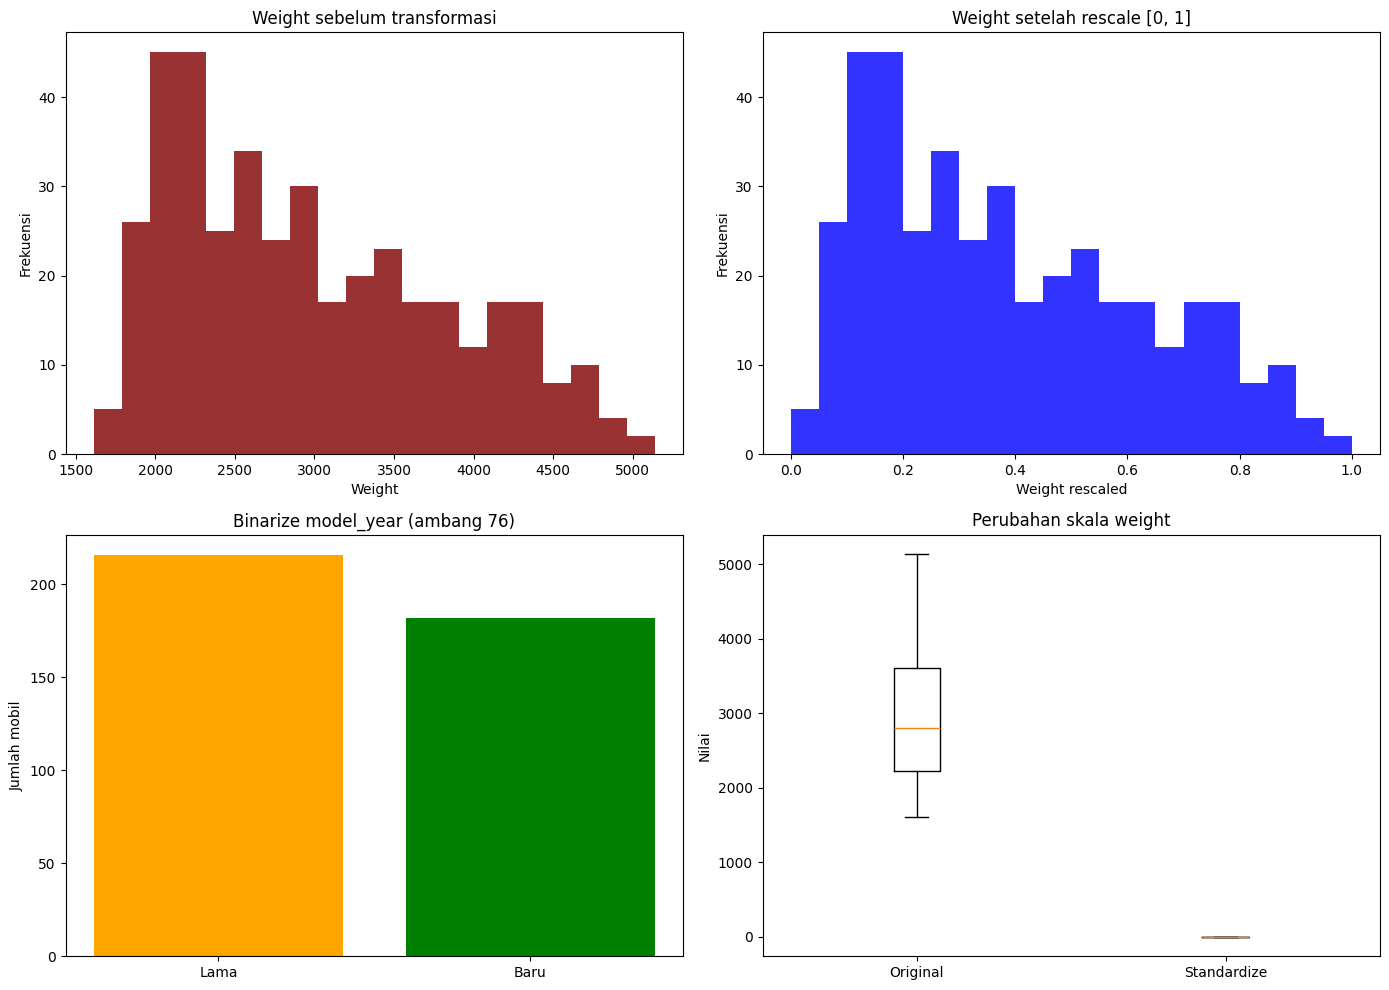

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(preprocess_df['weight'], bins=20, color='maroon', alpha=0.8)
axes[0, 0].set_title('Weight sebelum transformasi')
axes[0, 0].set_xlabel('Weight')
axes[0, 0].set_ylabel('Frekuensi')

axes[0, 1].hist(rescaled_df['weight'], bins=20, color='blue', alpha=0.8)
axes[0, 1].set_title('Weight setelah rescale [0, 1]')
axes[0, 1].set_xlabel('Weight rescaled')
axes[0, 1].set_ylabel('Frekuensi')

axes[1, 0].bar(['Lama', 'Baru'], binarized_df['model_year_binary'].value_counts().sort_index(),
               color=["orange", 'green'])
axes[1, 0].set_title(f'Binarize model_year (ambang {year_threshold:.0f})')
axes[1, 0].set_ylabel('Jumlah mobil')

axes[1, 1].boxplot([preprocess_df['weight'], standardized_df['weight']],
                   tick_labels=['Original', 'Standardize'])
axes[1, 1].set_title('Perubahan skala weight')
axes[1, 1].set_ylabel('Nilai')

plt.tight_layout()
plt.show()